In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the SMS Spam dataset

import pandas as pd

data_path = "data/SMSSpamCollection"

df = pd.read_csv(
    data_path,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="utf-8"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
# Explore the dataset

print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nLabel Distribution:")
print(df["label"].value_counts())

Dataset Shape:
(5572, 2)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB

Missing Values:
label      0
message    0
dtype: int64

Label Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [4]:
# Clean the dataset

print("Rows before cleaning:", len(df))

df = df.dropna()
df = df.drop_duplicates()

df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

df = df[df["label"].isin(["ham", "spam"])]
df = df[df["message"] != ""]

print("Rows after cleaning:", len(df))
print("Remaining missing values:")
print(df.isnull().sum())

print("\nCleaned dataset preview:")
df.head()

Rows before cleaning: 5572
Rows after cleaning: 5169
Remaining missing values:
label      0
message    0
dtype: int64

Cleaned dataset preview:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


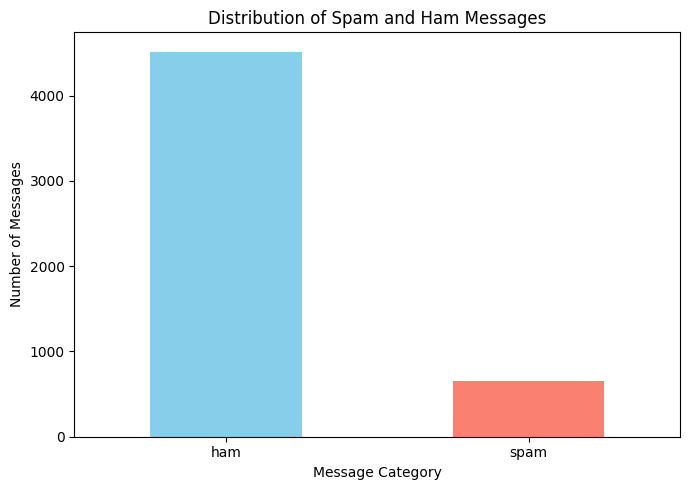

In [5]:
# Visualize the distribution of spam and ham messages

label_counts = df["label"].value_counts()

plt.figure(figsize=(7, 5))
label_counts.plot(kind="bar", color=["skyblue", "salmon"])

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
# Separate input features and target labels

X = df["message"]
y = df["label"]

print("Input features (X):")
print(X.head())

print("\nTarget labels (y):")
print(y.head())

print("\nTotal messages:", len(X))

Input features (X):
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: str

Target labels (y):
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: str

Total messages: 5169


In [7]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 4135
Testing messages: 1034


In [8]:
# Convert text messages into numerical features

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)
print("Text converted into numerical features successfully!")

Training data shape: (4135, 7414)
Testing data shape: (1034, 7414)
Text converted into numerical features successfully!


In [9]:

# Train the Spam Detection model

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("Spam Detection model trained successfully!")


Spam Detection model trained successfully!


In [10]:

# Make predictions on the test dataset

y_pred = model.predict(X_test_tfidf)

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label="spam"
)

recall = recall_score(
    y_test, y_pred, pos_label="spam"
)

f1 = f1_score(
    y_test, y_pred, pos_label="spam"
)

print("Model Evaluation Results")
print("-" * 30)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")


Model Evaluation Results
------------------------------
Accuracy:  0.9671
Precision: 1.0000
Recall:    0.7405
F1 Score:  0.8509


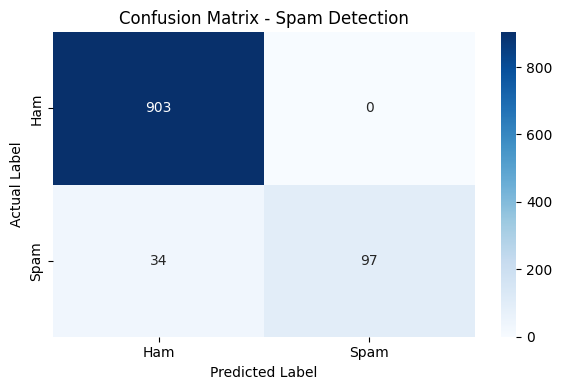

In [11]:

# Create the confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix - Spam Detection")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


In [12]:

print("Detailed Classification Report")
print(classification_report(y_test, y_pred))


Detailed Classification Report
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.96      1034



In [13]:

# Save the trained model and TF-IDF vectorizer

import joblib

joblib.dump(
    {
        "model": model,
        "vectorizer": vectorizer
    },
    "spam_detection_model.pkl"
)

print("Model and vectorizer saved successfully!")


Model and vectorizer saved successfully!


In [14]:

# Load the saved model

saved_data = joblib.load("spam_detection_model.pkl")

loaded_model = saved_data["model"]
loaded_vectorizer = saved_data["vectorizer"]

# Create new sample messages

new_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! You have won a cash reward. Call now!",
    "Please send me the notes from today's class."
]

# Convert messages into TF-IDF features

new_messages_tfidf = loaded_vectorizer.transform(new_messages)

# Predict message categories

predictions = loaded_model.predict(new_messages_tfidf)

# Display results

for message, prediction in zip(new_messages, predictions):
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print("-" * 50)


Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
--------------------------------------------------
Message: Hey, are we meeting for lunch today?
Prediction: HAM
--------------------------------------------------
Message: URGENT! You have won a cash reward. Call now!
Prediction: SPAM
--------------------------------------------------
Message: Please send me the notes from today's class.
Prediction: HAM
--------------------------------------------------


In [15]:

# Save model evaluation results

results_df = pd.DataFrame({
    "Actual_Label": y_test.reset_index(drop=True),
    "Predicted_Label": pd.Series(y_pred)
})

results_df["Correct_Prediction"] = (
    results_df["Actual_Label"] == results_df["Predicted_Label"]
)

results_df.to_csv("prediction_results.csv", index=False)

print("Prediction results saved successfully!")
results_df.head()


Prediction results saved successfully!


,Actual_Label,Predicted_Label,Correct_Prediction
0,ham,ham,True
1,ham,ham,True
2,ham,ham,True
3,ham,ham,True
4,ham,ham,True
